> **Business Objective**: Improve property inventory efficiency by increasing the conversion of properties and listings into completed transactions

> **Business Question** : How effectively is the current property inventory being converted into completed transactions?

# Import Library

In [37]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sklearn.preprocessing import MinMaxScaler

# Connection to Database

In [38]:
load_dotenv(".env")

conn = create_engine(
    f"postgresql://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
)

print("Connection created")

Connection created


# Property and Listing Analysis

## 
Retrive Data

In [39]:
dataset = '''
            SELECT
                l.listing_id
                ,l.agent_id
                ,t.transaction_id
                ,p.property_id
                ,l.listing_date
                ,l.listing_channel
                ,l.listing_status
                ,l.listed_price
                ,l.close_date
                ,t.deal_date
                ,t.deal_price
                ,t.deal_status
                ,t.commission_amount
                ,p.city AS prop_city
                ,p.property_type
                ,p.size_sqm
                ,p.bedrooms
                ,p.bathrooms
                ,p.location_score
                ,p.has_parking
                ,p.near_transit
                ,p.near_school
                ,p.list_price
                ,p.amenities_count
            FROM listings l
            FULL OUTER JOIN transactions t ON l.listing_id = t.listing_id
            FULL OUTER JOIN properties p ON l.property_id = p.property_id
            WHERE DATE_PART('year',listing_date)<=2024 OR listing_date IS NULL
            '''
df_dataset = pd.read_sql(dataset,conn)

In [40]:
df_dataset['deal_date'] = pd.to_datetime(df_dataset['deal_date']).astype('datetime64[ns]')
df_dataset['listing_date'] = pd.to_datetime(df_dataset['listing_date']).astype('datetime64[ns]')
df_dataset['close_date'] = pd.to_datetime(df_dataset['close_date']).astype('datetime64[ns]')


df_dataset['days_on_market'] = np.where(\
    df_dataset['close_date'].isna(),
    (pd.Timestamp('2024-12-31') - df_dataset['listing_date']).dt.days,
    (df_dataset['close_date'] - df_dataset['listing_date']).dt.days
)

bins_price = np.linspace(min(df_dataset['listed_price']),max(df_dataset['listed_price']),4)
category = ['cheap','medium','expensive']
df_dataset['listed_price_cat'] = pd.cut(df_dataset['listed_price'],bins_price,labels=category,include_lowest = True)

bins_size = np.linspace(min(df_dataset['size_sqm']),max(df_dataset['size_sqm']),4)
category = ['small','medium','large']
df_dataset['property_size_cat'] = pd.cut(df_dataset['size_sqm'],bins_size,labels=category,include_lowest = True)

bins_location_score = np.linspace(min(df_dataset['location_score']),max(df_dataset['location_score']),4)
category = ['low','medium','high']
df_dataset['location_score_cat'] = pd.cut(df_dataset['location_score'],bins_location_score,labels=category,include_lowest = True)

##
**Propertiy and Listing Overview**

In [41]:
df_listing = df_dataset[~df_dataset['listing_id'].isna()].reset_index(drop=True)

df_properties = df_dataset.drop_duplicates(subset = 'property_id').sort_values('property_id').reset_index(drop = True)
df_listed_prop = df_properties[~df_properties['listing_id'].isna()].reset_index(drop=True)
df_unlisted_prop = df_properties[df_properties['listing_id'].isna()]

df_transaction = df_dataset[(~df_dataset['transaction_id'].isna()) & ((df_dataset['deal_date'].dt.year)<=2024)].reset_index()
df_trans_prop = df_transaction.drop_duplicates('property_id').reset_index(drop=True)

df_completed = df_transaction[df_transaction['deal_status']=='Completed'].reset_index(drop=True)
df_transaction_prop_completed = df_completed.drop_duplicates(subset ='property_id')

In [42]:

df_property_type = (\
    df_dataset
    .groupby('property_type')
    .agg(total_listing = ('listing_id','nunique'),
         total_property = ('property_id','nunique'))
    .reset_index()
)
df_property_type['listing_share'] = (\
    round(
        (df_property_type['total_listing']/
         (df_property_type['total_listing'].sum()))*100,2
    )
)
df_property_type['property_share'] = (\
    round(
        (df_property_type['total_property']/
         (df_property_type['total_property'].sum()))*100,2
    )
)
df_city = (\
    df_dataset
        .groupby('prop_city')
        .agg(total_listing = ('listing_id','nunique'),
             total_property = ('property_id','nunique'))
        .reset_index()    
)
df_city['listing_share'] = (\
    round(
        (df_city['total_listing']/
         (df_city['total_listing'].sum()))*100,2
    )
)
df_city['property_share'] = (\
    round(
        (df_city['total_property']/
         (df_city['total_property'].sum()))*100,2
    )
)

variabel = {'Listing':df_listing,
               'Property' : df_properties,
               'Listed Property': df_listed_prop,
               'Unlisted Property' : df_unlisted_prop,
               'Transaction' : df_transaction,
               'Completed Transaction' : df_completed,
               'Property Sold': df_transaction_prop_completed} 

print(f'{"-"*20} Properties and Listing Overview {"-"*20}')
for x,y in variabel.items():
    print(f'Number of {x} = {len(y)}')

display(df_property_type)
display(df_city)

-------------------- Properties and Listing Overview --------------------
Number of Listing = 8500
Number of Property = 4500
Number of Listed Property = 3817
Number of Unlisted Property = 683
Number of Transaction = 3776
Number of Completed Transaction = 3737
Number of Property Sold = 2516


,property_type,total_listing,total_property,listing_share,property_share
0,Apartment,4683,2472,55.09,54.93
1,Commercial,695,371,8.18,8.24
2,House,2216,1165,26.07,25.89
3,Land,906,492,10.66,10.93


,prop_city,total_listing,total_property,listing_share,property_share
0,Barishal,612,326,7.20,7.24
1,Chattogram,1575,816,18.53,18.13
2,Dhaka,2527,1308,29.73,29.07
3,Khulna,959,500,11.28,11.11
4,Mymensingh,757,409,8.91,9.09
5,Rajshahi,724,408,8.52,9.07
6,Rangpur,697,381,8.20,8.47
7,Sylhet,649,352,7.64,7.82


##


##
**Property & Listings Conversion**

>What is the property and the listing conversion rate?

In [43]:
conversion_property = (
    round(
        (len(df_transaction_prop_completed)/
         len(df_properties))
        *100,0)
)

conversion_listing = (
    round(
        (len(df_completed)/
         len(df_listing))
         *100,0)
)


print(f'Convertion Rate of Property = {conversion_property}%')
print(f'Convertion Rate of Listing = {conversion_listing}%')

Convertion Rate of Property = 56.0%
Convertion Rate of Listing = 44.0%


##
**Annual Property & Listing Absorption Rate**

>How does property and listing inventory absorption change over time?

###
Annual Listing Absorption Rate

,year,available_listing,total_trans,absorption_rate
0,2022,2879,1121,38.94
1,2024,5318,1337,25.14
2,2023,4285,1279,29.85


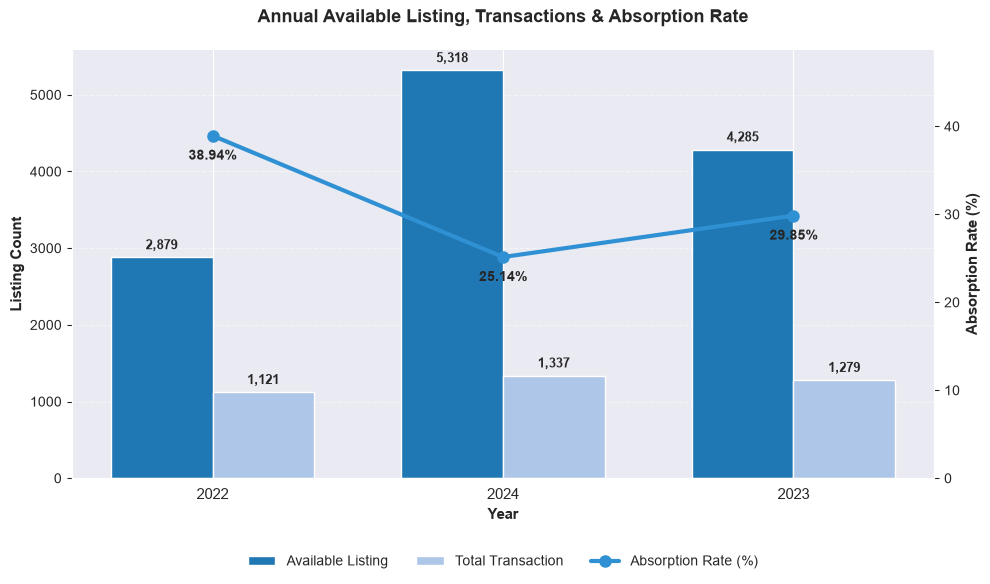

In [44]:
annual_available_listing = []
years = (df_listing['listing_date'].dt.year).unique()
for year in years:
    start_date = pd.Timestamp(f'{year}-01-01')
    end_date = pd.Timestamp(f'{year}-12-31')
    
    carry_over = df_dataset[
        (df_dataset['listing_date']< start_date ) &
        ((df_dataset['close_date'] >= start_date)|
         (df_dataset['close_date'].isna()))
    ]
    new_listing = df_dataset[
        (df_dataset['listing_date']>=start_date) &
        ((df_dataset['listing_date']<=end_date))]
    
    available_listing = (\
    carry_over['listing_id'].nunique() +
    new_listing['listing_id'].nunique()
    )

    annual_available_listing.append(
        {'year': year,
         'available_listing' : available_listing}
    )

annual_available_list = pd.DataFrame(annual_available_listing)

trans_year = (\
    df_completed
    .groupby(df_completed['deal_date'].dt.year)
    .agg(total_trans = ('transaction_id','count'))
    .reset_index()
    .rename(columns = {'deal_date':'year'})
    )

annual_absorption_rate = annual_available_list.merge(trans_year, on = 'year')

annual_absorption_rate['absorption_rate'] = (\
       annual_absorption_rate['total_trans']
       /annual_absorption_rate['available_listing']
         *100).round(2)
display(annual_absorption_rate)

#GRAFIK

sns.set_style("darkgrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

x = np.arange(len(annual_absorption_rate["year"]))
width = 0.35

rects1 = ax1.bar(\
    x - width / 2,
    annual_absorption_rate["available_listing"],
    width,
    label="Available Listing",
    color="#1f77b4",
)

rects2 = ax1.bar(\
    x + width / 2,
    annual_absorption_rate["total_trans"],
    width,
    label="Total Transaction",
    color="#aec7e8",
)

ax1.set_ylabel("Listing Count", fontsize=11, fontweight="bold")
ax1.set_xlabel("Year", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(annual_absorption_rate["year"].astype(str), fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax1.annotate(
        f"{int(height):,}",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

ax2 = ax1.twinx()

line_color = "#2f91d3"

line = ax2.plot(\
    x,
    annual_absorption_rate["absorption_rate"],
    color=line_color,
    marker="o",
    linewidth=3,
    markersize=8,
    label="Absorption Rate (%)",
)

ax2.set_ylabel("Absorption Rate (%)", fontsize=11, fontweight="bold")
ax2.tick_params(axis="y")
ax2.grid(False)

max_rate = annual_absorption_rate["absorption_rate"].max()
ax2.set_ylim(0, max_rate * 1.25)

for i, txt in enumerate(annual_absorption_rate["absorption_rate"]):
    ax2.annotate(\
        f"{txt:.2f}%",
        (x[i], txt),
        textcoords="offset points",
        xytext=(0, -10),
        ha="center",
        va = 'top',
        fontweight="bold",
        fontsize=10,
    )

plt.title(
    "Annual Available Listing, Transactions & Absorption Rate",
    fontsize=13,
    fontweight="bold",
    pad=20,
    loc="center",
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(\
    lines1 + lines2,
    labels1 + labels2,
    bbox_to_anchor=(0.5, -0.15),
    loc="upper center",
    ncol =3,
    frameon=True,
    facecolor="white",
    edgecolor="none",
)

sns.despine(top=True, right=False)
plt.tight_layout()
plt.show()




###
Annual Property Absorption Rate(%)

,year,available_property,total_trans,absorption_rate
0,2022,2133,993,46.55
1,2023,2219,1099,49.53
2,2024,1725,1161,67.30


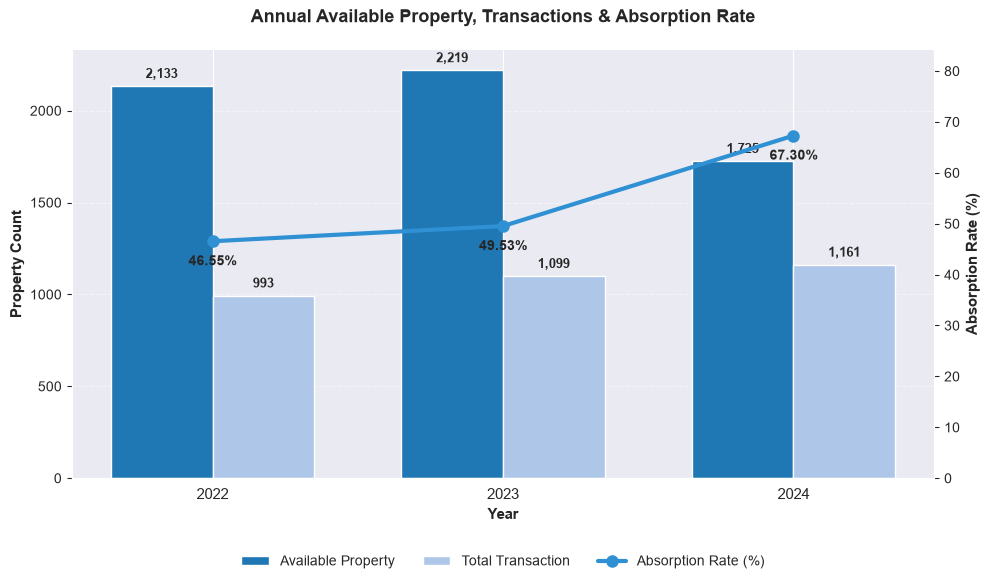

In [45]:
results = []
years = sorted(df_listing['listing_date'].dt.year.unique())

previous_stock_carry_over = 0
previous_stock_new = 0

for i, year in enumerate(years):
    start_date = pd.Timestamp(f'{year}-01-01')
    end_date = pd.Timestamp(f'{year}-12-31')

    
    historical_listings = df_listing[df_listing['listing_date'] < start_date]
    historical_ids = historical_listings['property_id'].unique()
    historical_sold = df_completed[df_completed['deal_date'] < start_date]
    historical_sold_ids = historical_sold['property_id'].unique()

    #Carry Over Properties
    if i == 0:
        active_historical_ids = np.setdiff1d(historical_ids, historical_sold_ids)
        carry_over_prop = len(active_historical_ids)
    else:
        
        carry_over_prop = previous_stock_carry_over + previous_stock_new

    # New Properties Listing
    new_listing_porp = df_listing[
        (df_listing['listing_date'] >= start_date) & 
        (df_listing['listing_date'] <= end_date)
    ]
    new_listing_prop_ids = new_listing_porp['property_id'].unique()
    new_property_ids = np.setdiff1d(new_listing_prop_ids, historical_ids)
    new_prop = len(new_property_ids)

    #Transaction Data
    prop_trans = df_completed[
        (df_completed['deal_date'] >= start_date) & 
        (df_completed['deal_date'] <= end_date)
    ]
    prop_trans_ids = prop_trans['property_id'].unique()
    
    new_prop_trans_ids = np.intersect1d(prop_trans_ids, new_property_ids)
    new_prop_trans = len(new_prop_trans_ids)
    
    total_prop_trans_count = len(prop_trans_ids)
    carry_over_trans = total_prop_trans_count - new_prop_trans

    
    previous_stock_carry_over = max(0, carry_over_prop - carry_over_trans)
    previous_stock_new = max(0, new_prop - new_prop_trans)

    results.append(
        {
            'year': year,
            'available_property' : new_prop + carry_over_prop,
            'total_trans': carry_over_trans + new_prop_trans

        }
    )


df_absorption_property = pd.DataFrame(results)

df_absorption_property['absorption_rate'] = (
    round((df_absorption_property['total_trans']/
    df_absorption_property['available_property'])*100,2)
)

display(df_absorption_property)

#GRAPH

sns.set_style("darkgrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

x = np.arange(len(df_absorption_property["year"]))
width = 0.35

rects1 = ax1.bar(\
    x - width / 2,
    df_absorption_property["available_property"],
    width,
    label="Available Property",
    color="#1f77b4",
)

rects2 = ax1.bar(\
    x + width / 2,
    df_absorption_property["total_trans"],
    width,
    label="Total Transaction",
    color="#aec7e8",
)

ax1.set_ylabel("Property Count", fontsize=11, fontweight="bold")
ax1.set_xlabel("Year", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(df_absorption_property["year"].astype(str), fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax1.annotate(
        f"{int(height):,}",
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

ax2 = ax1.twinx()

line_color = "#2f91d3"

line = ax2.plot(\
    x,
    df_absorption_property["absorption_rate"],
    color=line_color,
    marker="o",
    linewidth=3,
    markersize=8,
    label="Absorption Rate (%)",
)

ax2.set_ylabel("Absorption Rate (%)", fontsize=11, fontweight="bold")
ax2.tick_params(axis="y")
ax2.grid(False)

max_rate = df_absorption_property["absorption_rate"].max()
ax2.set_ylim(0, max_rate * 1.25)

for i, txt in enumerate(df_absorption_property["absorption_rate"]):
    ax2.annotate(\
        f"{txt:.2f}%",
        (x[i], txt),
        textcoords="offset points",
        xytext=(0, -10),
        ha="center",
        va = 'top',
        fontweight="bold",
        fontsize=10,
    )

plt.title(
    "Annual Available Property, Transactions & Absorption Rate",
    fontsize=13,
    fontweight="bold",
    pad=20,
    loc="center",
)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(\
    lines1 + lines2,
    labels1 + labels2,
    bbox_to_anchor=(0.5, -0.15),
    loc="upper center",
    ncol =3,
    frameon=True,
    facecolor="white",
    edgecolor="none",
)

sns.despine(top=True, right=False)
plt.tight_layout()
plt.show()


##
**Convertion Rate by Segment**

>Which segments have higher or lower conversion rates?

In [46]:
def call_analysis(df1, df2, df3, col):
    #Property Analisis
    total_prop = (
        df1.groupby(col)
        .agg(total_property=('property_id', 'nunique'))
        .reset_index()
    )
    
    total_trans = (
        df2.groupby(col)
        .agg(total_property_sold=('property_id', 'nunique'))
        .reset_index()
    )
    
    property_perform = total_prop.merge(total_trans, on=col, how='left').fillna(0)
    
    property_perform['prop_conversion_rate'] = round(
        (property_perform['total_property_sold'] /
          property_perform['total_property']) * 100, 2
    )
    
    # Listing Analysis
    total_list = (
        df3.groupby(col)
        .agg(total_listing=('listing_id', 'nunique'))
        .reset_index()
    )
    
    total_trans_listing = (
        df2.groupby(col)
        .agg(total_listing_completed=('listing_id', 'nunique'),
             avg_DOM = ('days_on_market','mean'))
        .reset_index() 
    )
    total_trans_listing['avg_DOM'] = round(total_trans_listing['avg_DOM'],0)
    listing_perform = total_list.merge(total_trans_listing, on=col, how='left').fillna(0)
    
    listing_perform['listing_conversion_rate'] = round(
        (listing_perform['total_listing_completed'] / listing_perform['total_listing']) * 100, 2
    )
    
    return property_perform, listing_perform



###
Conversion Rate by City

In [47]:
prop_city,list_city = call_analysis(df_properties,df_completed,df_listing,'prop_city')
display(prop_city,list_city)

,prop_city,total_property,total_property_sold,prop_conversion_rate
0,Barishal,326,195,59.82
1,Chattogram,816,446,54.66
2,Dhaka,1308,746,57.03
3,Khulna,500,275,55.00
4,Mymensingh,409,222,54.28
5,Rajshahi,408,224,54.90
6,Rangpur,381,203,53.28
7,Sylhet,352,205,58.24


,prop_city,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,Barishal,612,287,45.0,46.90
1,Chattogram,1575,678,45.0,43.05
2,Dhaka,2527,1124,44.0,44.48
3,Khulna,959,406,46.0,42.34
4,Mymensingh,757,321,45.0,42.40
5,Rajshahi,724,332,47.0,45.86
6,Rangpur,697,294,45.0,42.18
7,Sylhet,649,295,48.0,45.45


###
Conversion Rate by Property Type

In [48]:
prop_proptype, list_proptype = call_analysis(df_properties,df_completed,df_listing,'property_type')
display(prop_proptype,list_proptype)

,property_type,total_property,total_property_sold,prop_conversion_rate
0,Apartment,2472,1411,57.08
1,Commercial,371,196,52.83
2,House,1165,642,55.11
3,Land,492,267,54.27


,property_type,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,Apartment,4683,2127,44.0,45.42
1,Commercial,695,280,49.0,40.29
2,House,2216,958,47.0,43.23
3,Land,906,372,49.0,41.06


###
Coversion Rate by Channel

In [49]:
prop_chan,list_chan = call_analysis(df_properties,df_completed,df_listing,'listing_channel')
display(prop_chan,list_chan)


,listing_channel,total_property,total_property_sold,prop_conversion_rate
0,Exclusive,1674,1330,79.45
1,Open,1660,1409,84.88
2,Partner,483,457,94.62


,listing_channel,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,Exclusive,3605,1572,46.0,43.61
1,Open,3826,1687,45.0,44.09
2,Partner,1069,478,45.0,44.71


###
Conversion Rate by Price Category

In [50]:
prop_pricecat, list_pricecat = call_analysis(df_properties,df_completed,df_listing,'listed_price_cat')
display(prop_pricecat, list_pricecat)

,listed_price_cat,total_property,total_property_sold,prop_conversion_rate
0,cheap,3504,2330,66.50
1,medium,298,199,66.78
2,expensive,15,11,73.33


,listed_price_cat,total_listing,total_listing_completed,avg_DOM,listing_conversion_rate
0,cheap,7793,3448,45.0,44.24
1,medium,666,278,48.0,41.74
2,expensive,41,11,44.0,26.83


## 
**Conversion Rate by Property Characteristics**

> Which property characteristics are associated with higher property conversion?

Property Characteristics List = 

'property_size_cat', 'bedrooms', 'bathrooms', 

'location_score_cat', 'has_parking', 

'near_transit', 'near_school','list_price', 

'amenities_count'

In [51]:
columns = ['property_size_cat', 'bedrooms', 'bathrooms','location_score_cat', 
           'has_parking', 'near_transit', 'near_school', 'amenities_count']
property_perform = {}

for col in columns:
    total_prop = (
        df_properties
        .groupby(col)
        .agg(total_property=('property_id', 'nunique'))
        .reset_index()
    )
    
    total_trans = (
        df_completed.groupby(col)
        .agg(total_property_sold=('property_id', 'nunique'))
        .reset_index()
    )
    
    property_perform[col] = total_prop.merge(total_trans, on=col, how='left').fillna(0)
    
    property_perform[col]['conversion_rate'] = round(
        (property_perform[col]['total_property_sold'] /
          property_perform[col]['total_property']) * 100, 2
    )

for col, df_result in property_perform.items():
        print(f"---Property Conversion Rate by {col}---")
        display(df_result)
        print("\n")


---Property Conversion Rate by property_size_cat---


,property_size_cat,total_property,total_property_sold,conversion_rate
0,small,4133,2305,55.77
1,medium,357,206,57.70
2,large,10,5,50.00




---Property Conversion Rate by bedrooms---


,bedrooms,total_property,total_property_sold,conversion_rate
0,0,919,493,53.65
1,1,463,259,55.94
2,2,1243,706,56.80
3,3,1207,682,56.50
4,4,536,303,56.53
5,5,117,65,55.56
6,6,15,8,53.33




---Property Conversion Rate by bathrooms---


...

,near_transit,total_property,total_property_sold,conversion_rate
0,False,2224,1228,55.22
1,True,2276,1288,56.59




---Property Conversion Rate by near_school---


,near_school,total_property,total_property_sold,conversion_rate
0,False,2213,1233,55.72
1,True,2287,1283,56.10




---Property Conversion Rate by amenities_count---


,amenities_count,total_property,total_property_sold,conversion_rate
0,1.0,58,27,46.55
1,2.0,61,29,47.54
2,3.0,152,92,60.53
3,4.0,255,139,54.51
4,5.0,426,244,57.28
5,6.0,535,294,54.95
6,7.0,642,362,56.39
7,8.0,854,503,58.90
8,9.0,541,290,53.60
9,10.0,446,230,51.57


##
**Agent Coverage and Property Conversion Rate**

How does the number of agents assigned to a property relate to its conversion performance?

In [52]:
df_agent = df_dataset.groupby('agent_id').agg(total_list_props_handled = ('property_id','nunique'))
df_agent['property_sold'] = df_completed.groupby('agent_id')['transaction_id'].nunique()
df_agent['total_earning'] = df_completed.groupby('agent_id')['deal_price'].sum()
df_agent['conversion_rate'] = round((df_agent['property_sold']/df_agent['total_list_props_handled'])*100,2)
df_agent['market_share'] = round((df_agent['property_sold']/(df_agent['property_sold'].sum()))*100,2)
df_agent['revenue_share'] = round((df_agent['total_earning']/(df_agent['total_earning'].sum()))*100,2)
df_agent = df_agent.sort_values('market_share',ascending = False).reset_index()
df_agent


,agent_id,total_list_props_handled,property_sold,total_earning,conversion_rate,market_share,revenue_share
0,A00107,38,23,323458690.0,60.53,0.62,0.63
1,A00245,43,22,265002606.0,51.16,0.59,0.51
2,A00086,32,20,253555643.0,62.50,0.54,0.49
3,A00108,35,20,305356830.0,57.14,0.54,0.59
4,A00141,36,20,315409955.0,55.56,0.54,0.61
...,...,...,...,...,...,...,...
295,A00093,24,6,62200125.0,25.00,0.16,0.12
296,A00058,26,6,88414695.0,23.08,0.16,0.17
297,A00199,19,5,59515324.0,26.32,0.13,0.12
298,A00073,16,5,49502999.0,31.25,0.13,0.10


In [53]:
df_agent_perform = df_agent.copy()
df_agent_perform = (
    df_agent_perform
    .groupby('total_list_props_handled')
    .agg(num_of_agents = ('agent_id','nunique'),
        avg_conversion_rate = ('conversion_rate','mean'))
    .sort_values('num_of_agents',ascending = False)
    .reset_index()
)
df_agent_perform= df_agent_perform[['num_of_agents','total_list_props_handled' ,'avg_conversion_rate']]
df_agent_perform

,num_of_agents,total_list_props_handled,avg_conversion_rate
0,26,32,46.393846
1,23,29,46.327391
2,22,26,41.609091
3,22,25,42.181818
4,21,23,44.513810
5,20,28,39.644000
6,19,30,43.860000
7,19,24,43.420526
8,19,31,46.350000
9,17,27,42.918824


In [54]:
df_property = df_listing.copy()
df_property['num_agent_handling'] = df_property.groupby('property_id')['agent_id'].transform('nunique')
df_property =  df_property.drop_duplicates(subset ='property_id')
df_property = df_property[['property_id','num_agent_handling']]


df_prop_sold = df_completed.copy()
df_prop_sold['num_trans_prop'] = df_prop_sold.groupby('property_id')['transaction_id'].transform('nunique')
df_prop_sold = df_prop_sold.drop_duplicates(subset='property_id')
df_prop_sold = df_prop_sold[['property_id','num_trans_prop']]


df_dataprop = df_property.merge(df_prop_sold,on = 'property_id',how = 'left')
df_agent_perform = (
    df_dataprop
    .groupby('num_agent_handling')
    .agg(total_properties_handled = ('property_id','count'),
        total_sold = ('num_trans_prop','count')).reset_index()
)

df_agent_perform['conversion_rate'] = round((df_agent_perform['total_sold']/df_agent_perform['total_properties_handled'])*100,2)
df_agent_perform = df_agent_perform[['total_properties_handled','num_agent_handling','total_sold','conversion_rate']]
df_agent_perform

,total_properties_handled,num_agent_handling,total_sold,conversion_rate
0,1287,1,565,43.90
1,1225,2,831,67.84
2,768,3,622,80.99
3,336,4,305,90.77
4,132,5,124,93.94
5,50,6,50,100.00
6,15,7,15,100.00
7,3,8,3,100.00
8,1,9,1,100.00


##
**Unsold/Aging Metrics**

>Which properties or property segments are underperforming in terms of conversion?

###
Unsold Property Overview

In [55]:
df_active_listing = (
    df_listing[
        (df_listing['listing_status']=='Active')|
        (df_listing['close_date'].dt.year >=2025)]
        .reset_index(drop=True)
)
df_prop_active_list = df_active_listing.drop_duplicates(subset = 'property_id')

id_unsold_prop = df_prop_active_list['property_id']
id_sold_prop = df_transaction['property_id'].unique()

resell_prop = np.intersect1d(id_unsold_prop,id_sold_prop)

print(f'Number of Listing Aging = {len(df_active_listing)}')
print(f'Number of Unsold Property = {len(df_prop_active_list)}')
print(f'Number of Resell Property = {len(resell_prop)}')

Number of Listing Aging = 3125
Number of Unsold Property = 2082
Number of Resell Property = 815


###
Unsold Property by Segment

In [56]:
columns = ['prop_city','property_type','listing_channel','listed_price_cat']
unsold_property = {}

for col in columns:
    
    data = (df_prop_active_list
            .groupby(col)
            .agg(total_property_unsold = ('property_id','count')) 
            .reset_index()
    )
    
    unsold_property[col] = (
        data
        .sort_values('total_property_unsold',ascending=False)
        .reset_index(drop=True)
    )

for col, df_result in unsold_property.items():
        print(f"---Unsold Property by {col}---")
        display(df_result)


---Unsold Property by prop_city---


,prop_city,total_property_unsold
0,Dhaka,610
1,Chattogram,393
2,Khulna,241
3,Mymensingh,189
4,Rangpur,186
5,Rajshahi,170
6,Sylhet,156
7,Barishal,137


---Unsold Property by property_type---


,property_type,total_property_unsold
0,Apartment,1124
1,House,560
2,Land,229
3,Commercial,169


---Unsold Property by listing_channel---


,listing_channel,total_property_unsold
0,Open,911
1,Exclusive,909
2,Partner,262


---Unsold Property by listed_price_cat---


,listed_price_cat,total_property_unsold
0,cheap,1916
1,medium,158
2,expensive,8


###
Listing Aging Bucket


| Days Active  | Category          | Interpretation                                                                                                                           |
| ------------ | ----------------- | ---------------------------------------------------------------------------------------------------------------------------------------- |
| 0–90 days    | Fresh/New Listing | Newly added listings that are still within the initial marketing period and have higher potential to attract buyer interest.             |
| 91–180 days  | Normal Exposure   | Properties that remain within a reasonable market exposure period and are still considered actively marketable.                          |
| 181–365 days | Aging Listing     | Listings that require evaluation of pricing strategy, property positioning, and marketing efforts due to longer time on the market.      |
| 366–730 days | Long-Term Listing | Older listings that indicate slower sales movement and may reduce listing turnover and sales efficiency.                                 |
| >730 days    | Stale Listing     | Highly aged listings with a higher risk of remaining unsold, requiring significant strategy adjustments to improve conversion potential. |


In [57]:
bins = [
    0,
    90,
    180,
    365,
    730,
    float('inf')
]

category = [
    'Fresh/New Listing',
    'Normal Exposure',
    'Aging Listing',
    'Long-Term Listing',
    'Stale Listing'
]

df_active_listing['active_status'] = (\
    pd.cut(df_active_listing['days_on_market'],
           bins,
           labels = category,
           include_lowest = True)
)

listing_aging_prop = (\
    df_active_listing
    .groupby('active_status')
    .agg(total_property = ('property_id','nunique'))
)
listing_aging_prop['property_share'] = (
    round((listing_aging_prop['total_property']/
           (listing_aging_prop['total_property'].sum()))*100,2)
)

In [58]:
def call_crosstab (df,col1,col2,col3):
   df_crosstab = pd.crosstab(
                                    df[col1]
                                    ,df[col2]
                                    ,values=df[col3]
                                    ,aggfunc='nunique')

   return(df_crosstab)

In [59]:
columns = ['prop_city','property_type','listing_channel','listed_price_cat']
aging_share = {}

for col in columns:
    
    data = call_crosstab(df_active_listing,col,'active_status','property_id')
    
    aging_share[col] = data

for col, df_result in aging_share.items():
        print(f"{'-'*20} Aging Share by {col} {'-'*20}")
        display(df_result)

-------------------- Aging Share by prop_city --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing,Long-Term Listing,Stale Listing
prop_city,,,,,
Barishal,29,21,40,48,38
Chattogram,79,54,106,156,127
Dhaka,135,88,156,232,185
Khulna,52,44,63,92,74
Mymensingh,43,28,55,75,61
Rajshahi,31,26,50,57,62
Rangpur,38,36,40,86,58
Sylhet,32,24,39,61,51


-------------------- Aging Share by property_type --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing,Long-Term Listing,Stale Listing
property_type,,,,,
Apartment,253,168,310,404,333
Commercial,18,29,50,69,60
House,111,86,132,230,186
Land,57,38,57,104,77


-------------------- Aging Share by listing_channel --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing,Long-Term Listing,Stale Listing
listing_channel,,,,,
Exclusive,191,143,263,380,312
Open,199,152,241,399,325
Partner,64,37,78,126,82


-------------------- Aging Share by listed_price_cat --------------------


active_status,Fresh/New Listing,Normal Exposure,Aging Listing,Long-Term Listing,Stale Listing
listed_price_cat,,,,,
cheap,411.0,299.0,512.0,742.0,595.0
medium,26.0,21.0,36.0,69.0,64.0
expensive,2.0,2.0,1.0,4.0,NaN


###
Active Listing by Agent

In [60]:
df_agent_actv_list = (
    df_active_listing
    .groupby('agent_id')
    .agg(total_listing_active = ('listing_id','nunique'))
    .reset_index()
)

df_agent = df_agent.merge(df_agent_actv_list,on='agent_id',how = 'left')
df_agent

,agent_id,total_list_props_handled,property_sold,total_earning,conversion_rate,market_share,revenue_share,total_listing_active
0,A00107,38,23,323458690.0,60.53,0.62,0.63,12
1,A00245,43,22,265002606.0,51.16,0.59,0.51,14
2,A00086,32,20,253555643.0,62.50,0.54,0.49,11
3,A00108,35,20,305356830.0,57.14,0.54,0.59,11
4,A00141,36,20,315409955.0,55.56,0.54,0.61,11
...,...,...,...,...,...,...,...,...
295,A00093,24,6,62200125.0,25.00,0.16,0.12,9
296,A00058,26,6,88414695.0,23.08,0.16,0.17,7
297,A00199,19,5,59515324.0,26.32,0.13,0.12,6
298,A00073,16,5,49502999.0,31.25,0.13,0.10,6


##
Transaction Value & Commission by Segment

Which property segments generate the highest transaction value and commission?

In [61]:
columns = ['prop_city','property_type','listing_channel','listed_price_cat']
revenue_performance = {}

for col in columns:
    
    data = (df_completed
            .groupby(col)
            .agg(total_revenue = ('deal_price','sum'),
                 total_agent_commission=('commission_amount','sum'))
            .reset_index()
    )

    data['revenue_share'] = (
          round(
                (data['total_revenue']/
                 (data['total_revenue'].sum())
                 )*100,2
          )
    )
    revenue_performance[col] = (
        data
        .sort_values('total_revenue',ascending=False)
        .reset_index(drop=True)
    )

for col, df_result in revenue_performance.items():
        print(f"---Revenue Performance by {col}---")
        display(df_result)


---Revenue Performance by prop_city---


,prop_city,total_revenue,total_agent_commission,revenue_share
0,Dhaka,2.107547e+10,525000481.0,40.89
1,Chattogram,1.002952e+10,247645668.0,19.46
2,Khulna,4.370173e+09,107485376.0,8.48
3,Mymensingh,3.611587e+09,89259750.0,7.01
4,Sylhet,3.525160e+09,86495450.0,6.84
5,Rajshahi,3.392819e+09,83865848.0,6.58
6,Rangpur,2.876720e+09,70406973.0,5.58
7,Barishal,2.660260e+09,65827274.0,5.16


---Revenue Performance by property_type---


,property_type,total_revenue,total_agent_commission,revenue_share
0,Apartment,2.172824e+10,536479553.0,42.16
1,House,1.779648e+10,440424950.0,34.53
2,Commercial,7.208457e+09,181869564.0,13.99
3,Land,4.808529e+09,117212753.0,9.33


---Revenue Performance by listing_channel---


,listing_channel,total_revenue,total_agent_commission,revenue_share
0,Open,2.331081e+10,579371927.0,45.23
1,Exclusive,2.184554e+10,540743195.0,42.38
2,Partner,6.385356e+09,155871698.0,12.39


---Revenue Performance by listed_price_cat---


,listed_price_cat,total_revenue,total_agent_commission,revenue_share
0,cheap,4.180124e+10,1.031358e+09,81.10
1,medium,9.120170e+09,2.281255e+08,17.69
2,expensive,6.202992e+08,1.650346e+07,1.20


##
**Segment Resume Performance**

In [62]:

def resume_segment (list_df, prop_df, revenue_df, unsold_df, on_col):
    performance_df = (
        list_df
        .merge(prop_df, on=on_col, how='left')
        .merge(revenue_df, on=on_col, how='left')
        .merge(unsold_df, on=on_col, how='left')
    )
    
    desired_columns = [
        on_col, 'listing_conversion_rate', 'avg_DOM', 'prop_conversion_rate',
        'revenue_share', 'total_property_unsold', 'total_listing', 
        'total_listing_completed', 'total_property', 'total_property_sold',
        'total_revenue', 'total_agent_commission'
    ]
    
    existing_columns = [col for col in desired_columns if col in performance_df.columns]
    
    performance_df = (
        performance_df[existing_columns]
        .sort_values('revenue_share', ascending=False)
        .reset_index(drop=True)
    )
    
    return performance_df

###
City

In [63]:
df_unsold_property_city = unsold_property['prop_city']
df_revenue_performance_city = revenue_performance['prop_city']
city_performance = resume_segment(prop_city,list_city,df_revenue_performance_city,df_unsold_property_city,'prop_city')
city_performance

,prop_city,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,Dhaka,44.48,44.0,57.03,40.89,610,2527,1124,1308,746,2.107547e+10,525000481.0
1,Chattogram,43.05,45.0,54.66,19.46,393,1575,678,816,446,1.002952e+10,247645668.0
2,Khulna,42.34,46.0,55.00,8.48,241,959,406,500,275,4.370173e+09,107485376.0
3,Mymensingh,42.40,45.0,54.28,7.01,189,757,321,409,222,3.611587e+09,89259750.0
4,Sylhet,45.45,48.0,58.24,6.84,156,649,295,352,205,3.525160e+09,86495450.0
5,Rajshahi,45.86,47.0,54.90,6.58,170,724,332,408,224,3.392819e+09,83865848.0
6,Rangpur,42.18,45.0,53.28,5.58,186,697,294,381,203,2.876720e+09,70406973.0
7,Barishal,46.90,45.0,59.82,5.16,137,612,287,326,195,2.660260e+09,65827274.0


###
Property Type

In [64]:
df_unsold_property_proptype = unsold_property['property_type']
df_revenue_performance_proptype = revenue_performance['property_type']

proprtype_performance = resume_segment(prop_proptype, list_proptype,df_revenue_performance_proptype,df_unsold_property_proptype,'property_type')
proprtype_performance

,property_type,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,Apartment,45.42,44.0,57.08,42.16,1124,4683,2127,2472,1411,2.172824e+10,536479553.0
1,House,43.23,47.0,55.11,34.53,560,2216,958,1165,642,1.779648e+10,440424950.0
2,Commercial,40.29,49.0,52.83,13.99,169,695,280,371,196,7.208457e+09,181869564.0
3,Land,41.06,49.0,54.27,9.33,229,906,372,492,267,4.808529e+09,117212753.0


###
Listing Channel

In [65]:
df_unsold_property_channel = unsold_property['listing_channel']
df_revenue_performance_channel = revenue_performance['listing_channel']

channel_performance = resume_segment(prop_chan,list_chan,df_revenue_performance_channel,df_unsold_property_channel,'listing_channel')
channel_performance

,listing_channel,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,Open,44.09,45.0,84.88,45.23,911,3826,1687,1660,1409,2.331081e+10,579371927.0
1,Exclusive,43.61,46.0,79.45,42.38,909,3605,1572,1674,1330,2.184554e+10,540743195.0
2,Partner,44.71,45.0,94.62,12.39,262,1069,478,483,457,6.385356e+09,155871698.0


###
Listing Price Category

In [66]:
df_unsold_property_pricecat = unsold_property['listed_price_cat']
df_revenue_performance_pricecat = revenue_performance['listed_price_cat']

PriceCat_performance = resume_segment(prop_pricecat, list_pricecat,df_revenue_performance_pricecat,df_unsold_property_pricecat,'listed_price_cat')

PriceCat_performance

,listed_price_cat,listing_conversion_rate,avg_DOM,prop_conversion_rate,revenue_share,total_property_unsold,total_listing,total_listing_completed,total_property,total_property_sold,total_revenue,total_agent_commission
0,cheap,44.24,45.0,66.50,81.10,1916,7793,3448,3504,2330,4.180124e+10,1.031358e+09
1,medium,41.74,48.0,66.78,17.69,158,666,278,298,199,9.120170e+09,2.281255e+08
2,expensive,26.83,44.0,73.33,1.20,8,41,11,15,11,6.202992e+08,1.650346e+07
